# Exploratory data analysis

Exploration only: no result in the README depends on this notebook, and it writes no files.
It looks at the data behind the preprocessing of brief section 4 (re-closure, prevalence
filter, zero filter, log10(x + 1)) and at the D2/D3 facts that experiments E2–E4 rely on.

> **The external test cohort is deliberately not explored.** NLIBD (D1 `*_external.csv`) and
> its D2 copy (the Franzosa `Validation.*` rows) are opened only by the data checks of
> `make data` and to score final, fixed configurations (brief section 5): looking at them here
> could steer a threshold or a filter. This notebook never calls `data.load_nlibd` or
> `data.load_franzosa(part="Validation")`; the D1 and Franzosa loaders it does call return
> PRISM rows only. Every number computed below describes PRISM or the five D2 source
> datasets. Section 5b also quotes the brief's reference counts, which `make data` computed
> over all 220 Franzosa samples.

| Section | Data |
|---|---|
| 1. PRISM cohort | D1 PRISM: 155 samples, 200 species, 8,848 LC-MS features |
| 2. Taxon prevalence | D1 PRISM microbiome |
| 3. Metabolite zero fractions | D1 PRISM metabolome |
| 4. Intensity distributions | D1 PRISM metabolome |
| 5. D2 overview | D2 Franzosa (PRISM rows) and the five source datasets |
| 6. MGM vocabulary coverage | D1 PRISM microbiome and MGM's genus vocabulary (D3) |
| 7. Takeaways | |

Thresholds come from `configs/base.yaml` and expected data facts from
`configs/data_facts.yaml`; the constants defined below are display choices only.
Re-run with `make eda` (about 15 s on a laptop).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from scipy.stats import spearmanr

from m2m import data, mgm_io, paths, preprocess
from m2m.config import load_config
from m2m.experiments import common

CFG = load_config(paths.CONFIGS / "base.yaml")
FACTS = data.load_fact_specs()  # configs/data_facts.yaml, the values `make data` checks
ABUNDANCE_THRESHOLD = CFG["microbes"]["abundance_threshold"]  # a taxon is "present" above this
MIN_PREVALENCE = CFG["microbes"]["min_prevalence"]  # default prevalence filter
MAX_ZERO_FRACTION = CFG["metabolites"]["max_zero_fraction"]  # default target zero filter

# Display choices of this notebook; no model uses them.
PREVALENCE_THRESHOLDS = (0.05, 0.10, 0.20)  # the three arms of ablation A3 (brief section 6)
ZERO_FRACTION_EXAMPLES = (0.0, 0.1, 0.25, 0.4, 0.55, 0.7)  # section 4: one metabolite near each
LOW_SPECIES_TOTAL = 0.9  # section 1: below this a profile counts as visibly incomplete
JITTER_SEED = 0  # vertical jitter of the section-1 strip plot
MIN_INSIDE_LABEL = 25  # section 5b: narrower bar segments get no number inside

pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 90)

In [2]:
# Chart colours: one light-surface palette (the blue/orange pair and the blue ramp pass
# colour-vision-deficiency and contrast checks). A chart's single series wears BLUE; ORANGE
# marks the one subset a chart is about (zeros, section 4); GRAY de-emphasises what a filter
# drops; ordered categories use the blue ramp. Text always wears ink colours, never a series
# colour. Figures have an explicit light background so they stay legible in dark themes.
SURFACE = "#fcfcfb"
INK, INK_2 = "#0b0b0b", "#52514e"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#898781"
LIGHT_BLUE, MID_BLUE, DARK_BLUE = "#86b6ef", "#3987e5", "#184f95"  # ramp steps 250 / 400 / 600

plt.rcParams.update(
    {
        "figure.dpi": 100,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "font.family": "DejaVu Sans",
        "font.size": 9.5,
        "text.color": INK,
        "axes.titlesize": 10.5,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "legend.frameon": False,
        "legend.fontsize": 9,
        "lines.linewidth": 1.5,
        # Touching bars are separated by a thin gap in the surface colour, not by an outline.
        "patch.force_edgecolor": True,
        "patch.edgecolor": SURFACE,
        "patch.linewidth": 1.0,
    }
)


def value_grid(ax: plt.Axes, axis: str = "y") -> None:
    """Hairline grid on the value axis only, without tick marks."""
    ax.grid(axis=axis)
    ax.tick_params(axis=axis, length=0)


def threshold_line(ax: plt.Axes, x: float, label: str) -> None:
    """A labelled vertical reference line, drawn in ink rather than a series colour."""
    ax.axvline(x, color=INK_2, linewidth=1.0, zorder=3)
    # Right of the line, above the plot: close thresholds (5% and 10%) then never collide.
    ax.annotate(
        label,
        (x, 1.0),
        xycoords=ax.get_xaxis_transform(),
        xytext=(3, 2),
        textcoords="offset points",
        ha="left",
        va="bottom",
        color=INK_2,
        fontsize=8.5,
    )


def lc_ms_method(feature_ids: pd.Index) -> pd.Series:
    """LC-MS method of each D1 feature, read from its ID ("C18-neg_Cluster_0001" -> "C18-neg")."""
    return pd.Series([f.split("_", 1)[0] for f in feature_ids], index=feature_ids, name="method")


def dataset_label(dataset: str) -> str:
    """Short display name of a D2 dataset; Franzosa is only ever shown with its PRISM rows."""
    name = dataset.split("_", 1)[0]
    return f"{name} (PRISM rows)" if dataset == data.TARGET_DATASET else name


def shorten(text: str, width: int = 30) -> str:
    return text if len(text) <= width else text[: width - 1] + "…"

## 1. PRISM cohort

PRISM is the training cohort: 155 people, one stool sample each. D1's `diagnosis_PRISM.csv`
only says IBD or Healthy, so `load_prism` takes CD / UC / Control from the D2 Franzosa metadata
and checks that the two sources agree (DESIGN decision 1). These three classes stratify the
cross-validation folds.

In [3]:
prism = data.load_prism()
diagnosis = prism.meta["diagnosis"]
counts = pd.crosstab(diagnosis, prism.meta["ibd_status"], margins=True, margins_name="total")
counts.loc[[*data.DIAGNOSES, "total"]]

ibd_status,Healthy,IBD,total
diagnosis,,,
CD,0,68,68
UC,0,53,53
Control,34,0,34
total,34,121,155


**Why re-closure is needed.** D1 keeps only 200 MetaPhlAn2 species, so a sample's 200 relative
abundances sum to less than 1, short by whatever the dropped species carried. Each dot below is
one sample.

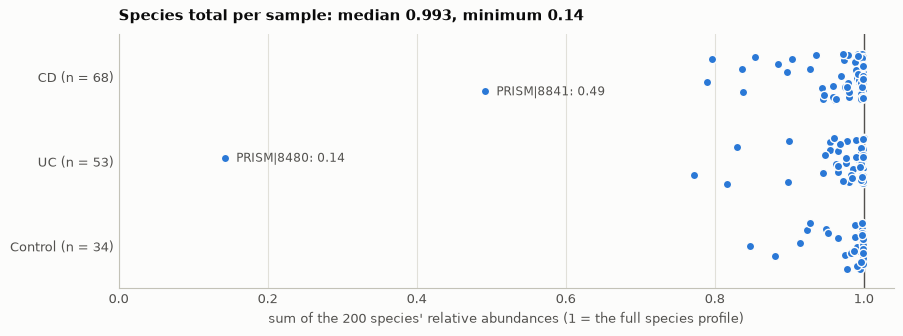

15 of 155 samples sum to less than 0.9 (CD 8, UC 5, Control 2)


In [4]:
species_total = prism.microbes.sum(axis=1)  # share of each profile carried by the 200 species
order = list(data.DIAGNOSES)
row = diagnosis.map({label: i for i, label in enumerate(order)}).astype(float)
y = row + np.random.default_rng(JITTER_SEED).uniform(-0.28, 0.28, len(row))

fig, ax = plt.subplots(figsize=(10, 3.3))
ax.scatter(species_total, y, s=36, color=BLUE, edgecolors=SURFACE, linewidths=1.0, zorder=3)
ax.axvline(1.0, color=INK_2, linewidth=1.0)
for sample in species_total.nsmallest(2).index:  # label the two extremes only
    ax.annotate(
        f"{sample}: {species_total[sample]:.2f}",
        (species_total[sample], y[sample]),
        xytext=(8, -3),
        textcoords="offset points",
        color=INK_2,
        fontsize=8.5,
    )
ax.set_yticks(range(len(order)), [f"{d} (n = {(diagnosis == d).sum()})" for d in order])
ax.set_ylim(len(order) - 0.5, -0.5)
ax.set_xlim(0, 1.04)
ax.set_xlabel("sum of the 200 species' relative abundances (1 = the full species profile)")
ax.set_title(
    f"Species total per sample: median {species_total.median():.3f}, "
    f"minimum {species_total.min():.2f}"
)
value_grid(ax, "x")
ax.tick_params(axis="y", length=0)
plt.show()

low = species_total < LOW_SPECIES_TOTAL
by_group = ", ".join(f"{d} {n}" for d, n in diagnosis[low].value_counts().items())
print(f"{low.sum()} of {len(low)} samples sum to less than {LOW_SPECIES_TOTAL} ({by_group})")

Half of the profiles lose less than 1%, but a few lose much more. Without re-closure every
abundance of `PRISM|8480` would be about 7 times smaller than in a complete profile of the same
composition, so the fixed 1e-4 presence threshold would mean something different in that
sample. `MicrobePreprocessor` therefore divides each row by its sum first. CLR itself would not
need it (a per-sample factor cancels, DESIGN decision 3); the presence threshold and the `log`
input ablation (A1) do. The low totals occur in all three diagnoses.

## 2. Taxon prevalence

A species' prevalence is the share of samples in which its re-closed relative abundance exceeds
1e-4. `MicrobePreprocessor.fit` keeps the species with prevalence ≥ 10% of the training samples
(`configs/base.yaml`); ablation A3 compares 5%, 10% and 20%. The counts below come from the
models' own preprocessor fitted on all 155 PRISM samples. Each CV fold refits the filter on its
training rows, so a fold's count can differ slightly.

In [5]:
relative = preprocess.closure(prism.microbes)  # the first step of MicrobePreprocessor.fit
prevalence = (relative > ABUNDANCE_THRESHOLD).mean()  # per species: share of samples present


def kept_species(min_prevalence: float) -> set[str]:
    """Species the models' microbe preprocessing keeps when fitted on all of PRISM."""
    section = {**CFG["microbes"], "min_prevalence": min_prevalence}
    return set(preprocess.MicrobePreprocessor.from_config(section).fit(prism.microbes).features_)


summary_rows = []
for threshold in PREVALENCE_THRESHOLDS:
    kept = kept_species(threshold)
    unclosed = set(preprocess.prevalent_taxa(prism.microbes, ABUNDANCE_THRESHOLD, threshold))
    summary_rows.append(
        {
            "min_prevalence": f"{threshold:.0%}",
            "species kept": len(kept),
            "kept without re-closure": len(unclosed),
            "same species": kept == unclosed,
        }
    )
prevalence_filter = pd.DataFrame(summary_rows).set_index("min_prevalence")

absent = prevalence.index[prevalence == 0].tolist()
print(f"{len(absent)} species never exceed {ABUNDANCE_THRESHOLD:g} in PRISM: {', '.join(absent)}")
prevalence_filter

6 species never exceed 0.0001 in PRISM: Methanobrevibacter_unclassified, Collinsella_stercoris, Bacteroides_clarus, Bacteroides_plebeius, Lactobacillus_delbrueckii, Lactobacillus_sakei


,species kept,kept without re-closure,same species
min_prevalence,,,
5%,184,184,True
10%,151,151,True
20%,109,109,True


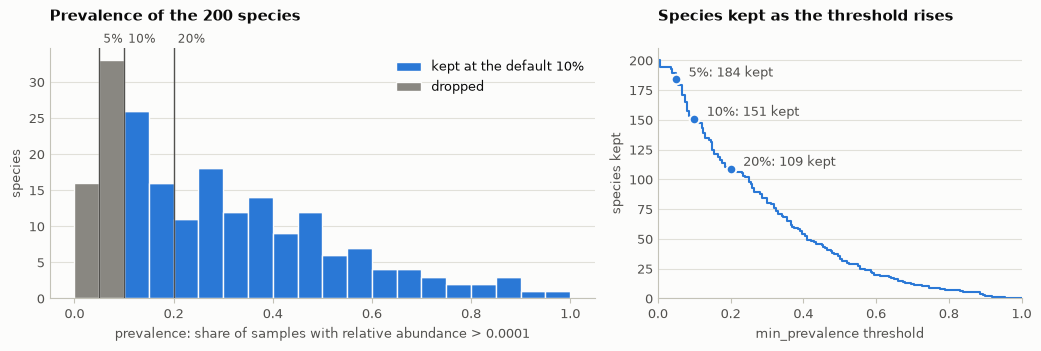

In [6]:
kept_default = prevalence >= MIN_PREVALENCE
fig, (ax_hist, ax_curve) = plt.subplots(
    1, 2, figsize=(10.5, 3.6), gridspec_kw={"width_ratios": [1.5, 1]}
)
ax_hist.hist(
    [prevalence[kept_default], prevalence[~kept_default]],
    bins=np.linspace(0, 1, 21),
    stacked=True,
    color=[BLUE, GRAY],
    label=[f"kept at the default {MIN_PREVALENCE:.0%}", "dropped"],
)
for threshold in PREVALENCE_THRESHOLDS:
    threshold_line(ax_hist, threshold, f"{threshold:.0%}")
ax_hist.set_xlabel(
    f"prevalence: share of samples with relative abundance > {ABUNDANCE_THRESHOLD:g}"
)
ax_hist.set_ylabel("species")
ax_hist.set_title(f"Prevalence of the {len(prevalence)} species", pad=20)
ax_hist.legend(loc="upper right")
value_grid(ax_hist)

threshold_grid = np.linspace(0, 1, 201)
ax_curve.step(
    threshold_grid, [(prevalence >= t).sum() for t in threshold_grid], where="post", color=BLUE
)
for threshold in PREVALENCE_THRESHOLDS:
    n_kept = prevalence_filter.loc[f"{threshold:.0%}", "species kept"]
    ax_curve.plot(
        threshold,
        n_kept,
        "o",
        markersize=7,
        color=BLUE,
        markeredgecolor=SURFACE,
        markeredgewidth=1.5,
        zorder=3,
    )
    ax_curve.annotate(
        f"{threshold:.0%}: {n_kept} kept",
        (threshold, n_kept),
        xytext=(9, 2),
        textcoords="offset points",
        color=INK_2,
    )
ax_curve.set_xlim(0, 1)
ax_curve.set_ylim(0, len(prevalence) * 1.05)
ax_curve.set_xlabel("min_prevalence threshold")
ax_curve.set_ylabel("species kept")
ax_curve.set_title("Species kept as the threshold rises", pad=20)
value_grid(ax_curve)
fig.tight_layout()
plt.show()

Prevalence is spread over the whole range: there is no natural gap for a threshold to sit in, so
each step from 5% to 20% removes a few dozen species. Re-closure changes no decision at these
thresholds: only the few incomplete profiles of section 1 change noticeably, and none of them
moves a species across a threshold. The species that are never above 1e-4 are absent from
every PRISM sample.

## 3. Metabolite zero fractions

A zero means the feature was not detected in that sample. `MetabolitePreprocessor.fit` drops a
target that is zero in more than 50% of the training samples (`max_zero_fraction`). Below, that
filter is fitted on all 155 PRISM samples with the models' own target preprocessing
(`common.metabolite_prep`) for both target sets: T466 (the 466 annotated metabolites) and TALL
(all 8,848 features). Each CV fold refits it on its training rows.

In [7]:
metabolites = prism.metabolites
zero_fraction = (metabolites == 0).mean()  # per feature: share of samples where not detected
fitted = {name: common.metabolite_prep(CFG, name).fit(metabolites) for name in common.TARGET_SETS}
pd.DataFrame(
    {
        name: {
            "candidates": prep.n_candidates_,
            "kept": len(prep.features_),
            "dropped by the zero filter": prep.n_dropped_zero_,
        }
        for name, prep in fitted.items()
    }
).T.rename_axis("target set")

,candidates,kept,dropped by the zero filter
target set,,,
T466,466,427,39
TALL,8848,6948,1900


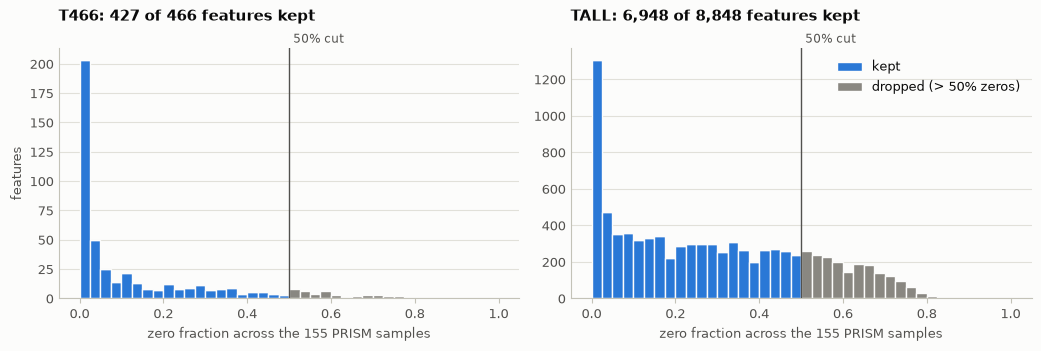

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
for ax, (name, prep) in zip(axes, fitted.items(), strict=True):
    candidates = (
        metabolites.columns
        if prep.candidate_features is None
        else pd.Index(prep.candidate_features)
    )
    values = zero_fraction[candidates]
    kept = candidates.isin(prep.features_)
    ax.hist(
        [values[kept], values[~kept]],
        bins=np.linspace(0, 1, 41),
        stacked=True,
        color=[BLUE, GRAY],
        label=["kept", f"dropped (> {MAX_ZERO_FRACTION:.0%} zeros)"],
    )
    threshold_line(ax, MAX_ZERO_FRACTION, f"{MAX_ZERO_FRACTION:.0%} cut")
    ax.set_title(f"{name}: {kept.sum():,} of {len(candidates):,} features kept", pad=20)
    ax.set_xlabel(f"zero fraction across the {len(metabolites)} PRISM samples")
    value_grid(ax)
axes[0].set_ylabel("features")
axes[1].legend(loc="upper right")  # the empty corner of the TALL panel
fig.tight_layout()
plt.show()

By LC-MS method (the prefix of each feature ID). T466 membership and the kept sets come from the
fitted preprocessors above.

In [9]:
method = lc_ms_method(metabolites.columns)
per_feature = pd.DataFrame(
    {
        "method": method,
        "zero_fraction": zero_fraction,
        "kept": metabolites.columns.isin(fitted["TALL"].features_),
        "T466": metabolites.columns.isin(fitted["T466"].candidate_features),
        "T466_kept": metabolites.columns.isin(fitted["T466"].features_),
    }
)


def zero_filter_summary(rows: pd.DataFrame) -> dict[str, float]:
    return {
        "features": len(rows),
        "median zero fraction": rows["zero_fraction"].median(),
        "kept": rows["kept"].sum(),
        "kept %": round(100 * rows["kept"].mean(), 1),
        "T466 features": rows["T466"].sum(),
        "T466 kept": rows["T466_kept"].sum(),
    }


by_method = {m: zero_filter_summary(rows) for m, rows in per_feature.groupby("method")}
by_method["all methods"] = zero_filter_summary(per_feature)
counts_only = {"features": int, "kept": int, "T466 features": int, "T466 kept": int}
pd.DataFrame(by_method).T.astype(counts_only).rename_axis("LC-MS method")

,features,median zero fraction,kept,kept %,T466 features,T466 kept
LC-MS method,,,,,,
C18-neg,2177,0.329,1572,72.2,75,69
C8-pos,2439,0.297,1785,73.2,179,151
HILIC-neg,1856,0.161,1616,87.1,102,101
HILIC-pos,2376,0.226,1975,83.1,110,106
all methods,8848,0.258,6948,78.5,466,427


The filter removes about a fifth of all features but only one annotated metabolite in twelve:
the annotated metabolites are detected more consistently than the unannotated features.
HILIC-neg features are detected most consistently, C18-neg and C8-pos features least.

## 4. Intensity distributions

The D1 values are not raw peak areas. Within each LC-MS method every sample sums to 1,000,000
up to rounding (table below): the release is total-sum normalised per method, i.e. parts per
million of the method's signal. The model targets are log10(x + 1) of these values, z-scored with training
statistics.

In [10]:
method_totals = metabolites.T.groupby(method).sum().T  # samples x LC-MS methods
intensities = metabolites.to_numpy()
detected = intensities[intensities > 0]
print(
    f"{detected.size:,} detected values: 1st percentile {np.quantile(detected, 0.01):.1f}, "
    f"median {np.median(detected):.0f}, maximum {detected.max():,.0f}; "
    f"{np.mean(detected < 1):.2%} are below 1, where the +1 of log10(x + 1) dominates"
)
method_totals.agg(["min", "median", "max"]).round().astype(int)

977,874 detected values: 1st percentile 2.9, median 71, maximum 385,626; 0.27% are below 1, where the +1 of log10(x + 1) dominates


method,C18-neg,C8-pos,HILIC-neg,HILIC-pos
min,999999,999999,999999,999999
median,1000000,1000000,1000000,1000000
max,1000001,1000001,1000001,1000000


Six annotated metabolites, picked by a rule rather than by hand: for each zero fraction in
`ZERO_FRACTION_EXAMPLES`, the T466 feature closest to it (ties: the highest median detected
value). Zeros (orange) land at log10(1) = 0, far below the detected values.

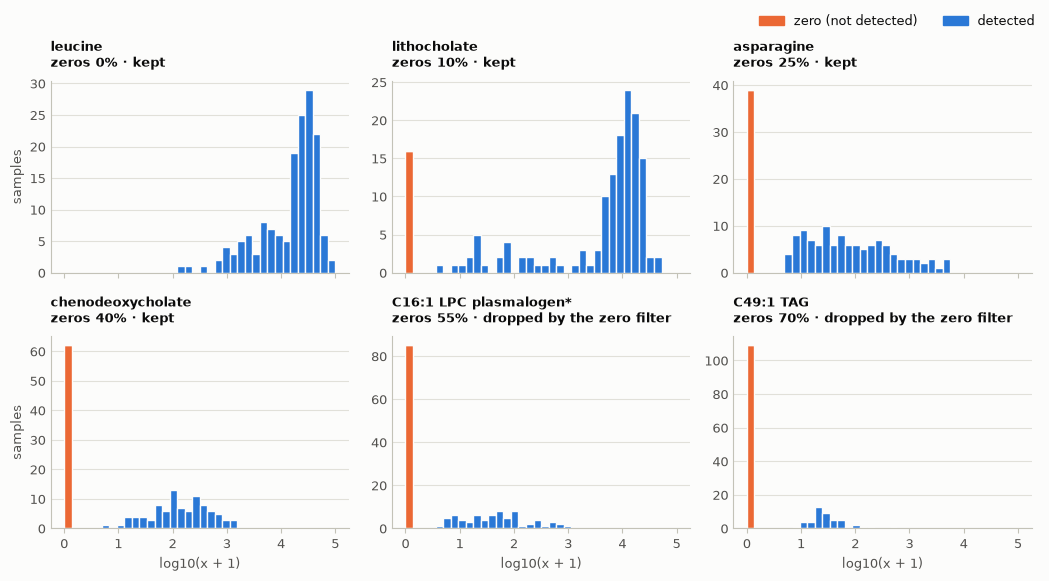

,compound,zero fraction,median detected value,kept by the zero filter
feature,,,,
HILIC-neg_Cluster_0105,leucine,0.000,23804.400,True
HILIC-neg_Cluster_1303,lithocholate,0.103,9808.900,True
HILIC-pos_Cluster_0099,asparagine,0.252,64.472,True
C18-neg_Cluster_1060,chenodeoxycholate,0.400,124.309,True
HILIC-pos_Cluster_1773,C16:1 LPC plasmalogen*,0.548,43.445,False
C8-pos_Cluster_2022,C49:1 TAG,0.703,24.611,False


In [11]:
def pick_examples(
    zero_fraction: pd.Series, detected_median: pd.Series, targets: tuple[float, ...]
) -> list[str]:
    """For each target zero fraction, the feature closest to it (ties: highest median)."""
    chosen = []
    for target in targets:
        distance = (zero_fraction - target).abs()
        tied = distance.index[distance == distance.min()]
        chosen.append(detected_median[tied].idxmax())
    return chosen


t466 = list(fitted["T466"].candidate_features)
annotated = metabolites[t466]
detected_median = annotated.where(annotated > 0).median()
examples = pick_examples(zero_fraction[t466], detected_median, ZERO_FRACTION_EXAMPLES)
compound = data.load_annotation()["Compound Name"]
logged = np.log10(metabolites[examples] + 1.0)

fig, axes = plt.subplots(2, 3, figsize=(10.5, 5.6), sharex=True)
bins = np.linspace(0, np.ceil(logged.to_numpy().max()), 37)
for ax, feature in zip(axes.flat, examples, strict=True):
    is_zero = metabolites[feature] == 0
    ax.hist(
        [logged.loc[is_zero, feature], logged.loc[~is_zero, feature]],
        bins=bins,
        stacked=True,
        color=[ORANGE, BLUE],
    )
    status = "kept" if feature in fitted["T466"].features_ else "dropped by the zero filter"
    ax.set_title(
        f"{shorten(compound[feature])}\nzeros {zero_fraction[feature]:.0%} · {status}",
        fontsize=9.5,
    )
    value_grid(ax)
for ax in axes[-1]:
    ax.set_xlabel("log10(x + 1)")
for ax in axes[:, 0]:
    ax.set_ylabel("samples")
fig.legend(
    handles=[Patch(color=ORANGE, label="zero (not detected)"), Patch(color=BLUE, label="detected")],
    loc="upper right",
    ncol=2,
    bbox_to_anchor=(1.0, 1.04),
)
fig.tight_layout()
plt.show()

pd.DataFrame(
    {
        "compound": compound[examples],
        "zero fraction": zero_fraction[examples],
        "median detected value": detected_median[examples],
        "kept by the zero filter": [f in fitted["T466"].features_ for f in examples],
    }
).rename_axis("feature")

Detected values are mostly far above 1 (1st percentile 2.9), so the +1 of log10(x + 1) barely
compresses them, and typical levels differ by orders of magnitude between metabolites (z-scoring
each target removes that). Zeros, in contrast, land at 0, below even the lowest detected value
and far below the typical one: after the transform a zero-inflated target is a spike plus a
separate bump, which z-scoring does not remove. The 50% zero filter drops the extreme cases.

## 5. D2 overview

D2 is the curated microbiome–metabolome collection (GTDB genus profiles). FRANZOSA_IBD_2019 is
the target dataset and holds the same people as D1: 155 `PRISM.*` samples and 65 `Validation.*`
samples (= NLIBD). Only its PRISM rows are loaded here (`load_franzosa(part="PRISM")`). The five
other datasets are the pretraining sources of E4.

### 5a. Samples and subjects

In [12]:
franzosa_prism = data.load_franzosa(part="PRISM", with_metabolites=False)  # PRISM rows only
sources = data.load_sources(drop_duplicates=False)  # as published; duplicates: section 5c
cohorts = {data.TARGET_DATASET: franzosa_prism, **sources}


def describe_dataset(name: str, cohort: data.Cohort) -> dict[str, object]:
    meta, mtb_map = cohort.meta, data.load_d2_mtb_map(name)
    groups = meta["diagnosis"].value_counts()
    return {
        "samples": len(meta),
        "subjects": meta["subject"].nunique(),
        "max samples per subject": meta["subject"].value_counts().max(),
        "Study.Group": ", ".join(f"{group} {n}" for group, n in groups.items()),
        "genus columns": cohort.microbes.shape[1],
        "metabolite features": len(mtb_map),
        "HMDB-mapped": mtb_map["HMDB"].notna().sum(),
    }


overview = pd.DataFrame({dataset_label(n): describe_dataset(n, c) for n, c in cohorts.items()})
# MARS's compound IDs name the panel they come from ("NMR_Lactate", "BA_Metabolites_...").
mars_panels = data.load_d2_mtb_map("MARS_IBS_2020").index.str.split("_").str[0]
mars_counts = mars_panels.value_counts(sort=False)
print("MARS compound-ID prefixes: " + ", ".join(f"{p} {n}" for p, n in mars_counts.items()))
overview.T

MARS compound-ID prefixes: NMR 19, Tryptophan 12, BA 12


,samples,subjects,max samples per subject,Study.Group,genus columns,metabolite features,HMDB-mapped
FRANZOSA (PRISM rows),155,155,1,"CD 68, UC 53, Control 34",11720,8848,278
iHMP,382,105,7,"CD 177, nonIBD 104, UC 101",9694,81867,507
YACHIDA,347,347,1,"Healthy 127, Stage_I_II 69, Stage_III_IV 54, MP 40, HS 30, Stage_0 27",11942,450,421
WANG,287,287,1,"ESRD 220, Control 67",11845,276,163
ERAWIJANTARI,96,96,1,"Healthy 54, Gastrectomy 42",10527,524,490
MARS,444,75,8,"D 172, H 139, C 133",2895,43,40


iHMP and MARS are longitudinal (several samples per subject), so their splits are grouped by
subject (brief section 5). Only iHMP shares PRISM's Broad LC-MS methods; the other metabolomes
come from other platforms (MARS, for example, combines 19 NMR compounds with 12 tryptophan
metabolites and 12 bile acids: the ID prefixes printed above), so only HMDB-mapped compounds
can be matched across datasets. `Study.Group` values are shown as published.

### 5b. Prevalent genera and their overlaps

A genus is prevalent in a dataset if its relative abundance exceeds 1e-4 in at least 10% of the
dataset's samples (the rule of section 2). The brief's numbers (`configs/data_facts.yaml`,
checked by `make data`) count Franzosa over all 220 samples. Here Franzosa means its 155 PRISM
rows only, so some numbers differ slightly from the brief's (table below). Descriptive only:
models refit the filter on their own training rows.

In [13]:
def prevalent_genera(cohort: data.Cohort) -> set[str]:
    relative = preprocess.closure(cohort.microbes)  # D2 rows already sum to 1 (`make data`)
    return set(preprocess.prevalent_taxa(relative, ABUNDANCE_THRESHOLD, MIN_PREVALENCE))


prevalent = {name: prevalent_genera(cohort) for name, cohort in cohorts.items()}
franzosa, ihmp = prevalent[data.TARGET_DATASET], prevalent[data.IHMP]
brief = {key: spec["expected"] for key, spec in FACTS.items()}
pd.DataFrame(
    {
        "brief (Franzosa = all 220 samples)": [
            brief["d2.prevalent_genera"][data.TARGET_DATASET],
            brief["d2.prevalent_genera"][data.IHMP],
            brief["d2.prevalent_genera_all_six"],
            brief["d2.prevalent_genera_union"],
            brief["d2.prevalent_genera_franzosa_ihmp"],
        ],
        "here (Franzosa = 155 PRISM rows)": [
            len(franzosa),
            len(ihmp),
            len(set.intersection(*prevalent.values())),
            len(set.union(*prevalent.values())),
            len(franzosa & ihmp),
        ],
    },
    index=[
        "prevalent in Franzosa",
        "prevalent in iHMP",
        "prevalent in all six datasets",
        "prevalent in at least one (union)",
        "prevalent in both Franzosa and iHMP",
    ],
)

,brief (Franzosa = all 220 samples),here (Franzosa = 155 PRISM rows)
prevalent in Franzosa,350,354
prevalent in iHMP,262,262
prevalent in all six datasets,213,214
prevalent in at least one (union),460,461
prevalent in both Franzosa and iHMP,241,241


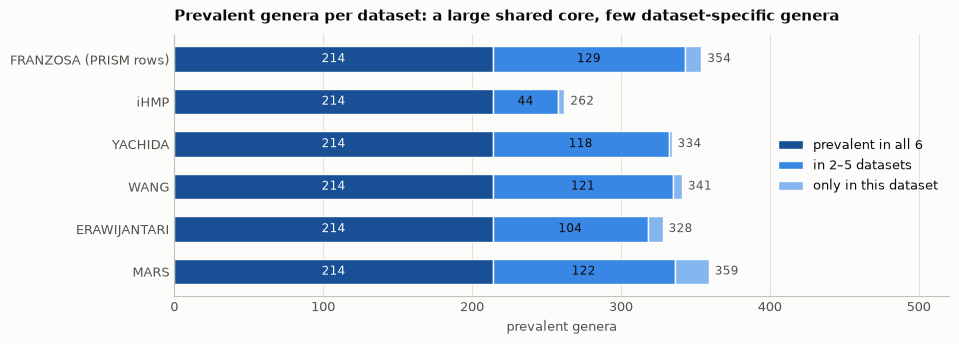

In [14]:
n_datasets = len(prevalent)
in_how_many = pd.Series([g for genera in prevalent.values() for g in genera]).value_counts()


def overlap_segments(genera: set[str]) -> dict[str, int]:
    """A dataset's prevalent genera, split by how many of the six datasets share them."""
    shared_by = in_how_many[list(genera)]
    return {
        f"prevalent in all {n_datasets}": int((shared_by == n_datasets).sum()),
        f"in 2–{n_datasets - 1} datasets": int(shared_by.between(2, n_datasets - 1).sum()),
        "only in this dataset": int((shared_by == 1).sum()),
    }


segments = pd.DataFrame({dataset_label(n): overlap_segments(g) for n, g in prevalent.items()}).T

fig, ax = plt.subplots(figsize=(10, 3.4))
left = np.zeros(len(segments))
colours = [(DARK_BLUE, SURFACE), (MID_BLUE, INK), (LIGHT_BLUE, INK)]  # (fill, inside text)
for column, (fill, ink) in zip(segments.columns, colours, strict=True):
    widths = segments[column].to_numpy()
    bars = ax.barh(segments.index, widths, left=left, height=0.6, color=fill, label=column)
    inside = [str(w) if w >= MIN_INSIDE_LABEL else "" for w in widths]
    ax.bar_label(bars, labels=inside, label_type="center", color=ink, fontsize=8.5)
    left += widths
for y_pos, total in enumerate(left):
    ax.text(total + 4, y_pos, f"{total:.0f}", va="center", color=INK_2, fontsize=8.5)
ax.invert_yaxis()
ax.set_xlim(0, left.max() * 1.45)
ax.set_xlabel("prevalent genera")
ax.set_title("Prevalent genera per dataset: a large shared core, few dataset-specific genera")
ax.legend(loc="center right")
value_grid(ax, "x")
ax.tick_params(axis="y", length=0)
plt.show()

### 5c. YACHIDA / ERAWIJANTARI duplicates

ERAWIJANTARI's metadata flags 53 samples `Shared.w.YACHIDA_2019` (and YACHIDA flags 53 samples
`Shared.w.ERAWIJANTARI_2020`). If they are the same metagenomes, keeping both copies would put
one person on both sides of a pretraining validation split. Check: for every ERAWIJANTARI
sample, the closest YACHIDA genus profile and their largest absolute difference.

In [15]:
def closest_profiles(a: pd.DataFrame, b: pd.DataFrame) -> pd.DataFrame:
    """For each row of `a`: the most similar row of `b` and their largest absolute difference.

    Genera missing from one table count as 0 there (D2 datasets list different genera).
    """
    columns = a.columns.union(b.columns)
    a_values = a.reindex(columns=columns, fill_value=0.0).to_numpy()
    b_values = b.reindex(columns=columns, fill_value=0.0).to_numpy()
    distance = np.array([np.abs(b_values - row).max(axis=1) for row in a_values])
    return pd.DataFrame(
        {"closest": b.index[distance.argmin(axis=1)], "max_abs_diff": distance.min(axis=1)},
        index=a.index,
    )


def duplicate_summary(rows: pd.DataFrame) -> dict[str, object]:
    diff = rows["max_abs_diff"]
    identical = f"identical to a YACHIDA profile (max |diff| < {data.IDENTITY_TOL:g})"
    return {
        "samples": len(rows),
        identical: rows["identical"].sum(),
        "closest YACHIDA profile: max |diff| (range)": f"{diff.min():.1e} to {diff.max():.1e}",
        "closest YACHIDA sample has the same number": rows["same_number"].sum(),
    }


erawijantari, yachida = sources[data.DUPLICATED_IN], sources[data.DUPLICATE_KEPT_IN]
match = closest_profiles(erawijantari.microbes, yachida.microbes)
match["identical"] = match["max_abs_diff"] < data.IDENTITY_TOL
# The shared samples keep their YACHIDA number: ERAWIJANTARI '10025.Healthy' vs YACHIDA '10025'.
match["same_number"] = [
    sample.split(".", 1)[0] == closest
    for sample, closest in zip(match.index, match["closest"], strict=True)
]
flagged = erawijantari.meta[data.DUPLICATE_FLAG].to_numpy()
deduplicated = data.drop_duplicate_samples(sources)
print(
    f"source metagenomes: {sum(len(c.meta) for c in sources.values()):,} as published, "
    f"{sum(len(c.meta) for c in deduplicated.values()):,} after load_sources() drops the "
    f"flagged {dataset_label(data.DUPLICATED_IN)} copies"
)
pd.DataFrame(
    {
        f"flagged {data.DUPLICATE_FLAG}": duplicate_summary(match[flagged]),
        "not flagged": duplicate_summary(match[~flagged]),
    }
)

source metagenomes: 1,556 as published, 1,503 after load_sources() drops the flagged ERAWIJANTARI copies


,flagged Shared.w.YACHIDA_2019,not flagged
samples,53,43
identical to a YACHIDA profile (max |diff| < 1e-06),53,0
closest YACHIDA profile: max |diff| (range),0.0e+00 to 1.6e-07,2.0e-02 to 2.2e-01
closest YACHIDA sample has the same number,53,0


The flag and profile identity agree exactly: every flagged sample is a YACHIDA metagenome
published twice (largest difference 1.6e-7, against at least 0.02 for every unflagged sample).
Hence `load_sources()` drops the ERAWIJANTARI copies by default (DESIGN decision 9).

### 5d. iHMP missing values by LC-MS method

iHMP is the only source measured with the same Broad LC-MS methods as PRISM. Its HMDB-mapped
table (the only part the loader reads) has no zeros; values that were not observed are missing
(NaN) instead. Is the missingness structured, e.g. a sample missing a whole LC-MS run?

In [16]:
ihmp_values = data.load_d2(data.IHMP, with_metabolites=True, hmdb_only=True).metabolites
ihmp_method = data.load_d2_mtb_map(data.IHMP).loc[ihmp_values.columns, "Method"]
missing = ihmp_values.isna()
per_sample = missing.T.groupby(ihmp_method).mean().T  # samples x methods: share missing

raw = ihmp_values.to_numpy()
print(
    f"{np.isnan(raw).mean():.1%} of {raw.size:,} values missing; observed values: "
    f"{int((raw == 0).sum())} zeros, minimum {np.nanmin(raw):g}, maximum {np.nanmax(raw):.2g}"
)
pd.DataFrame(
    {
        "features": ihmp_method.value_counts(),
        "missing %": 100 * missing.mean().groupby(ihmp_method).mean(),
        "features never missing": (~missing.any()).groupby(ihmp_method).sum(),
        "per-sample missing %, median": 100 * per_sample.median(),
        "per-sample missing %, max": 100 * per_sample.max(),
        "samples missing the whole method": (per_sample == 1).sum(),
    }
).round(1).rename_axis("LC-MS method")

8.2% of 193,674 values missing; observed values: 0 zeros, minimum 5, maximum 3e+10


,features,missing %,features never missing,"per-sample missing %, median","per-sample missing %, max",samples missing the whole method
LC-MS method,,,,,,
C18-neg,87,6.3,61,5.7,13.8,0
C8-pos,134,8.3,51,7.5,29.9,0
HILIC-neg,115,8.7,66,8.7,17.4,0
HILIC-pos,171,8.9,51,7.6,44.4,0


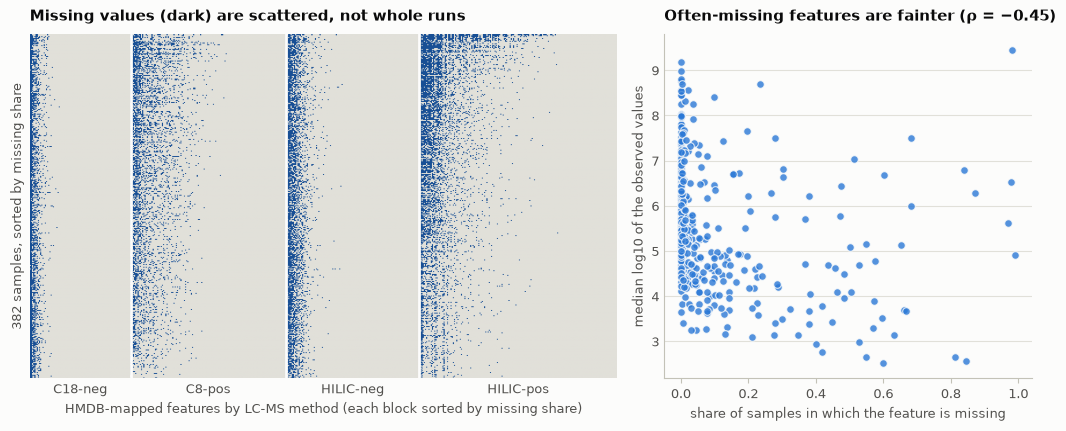

In [17]:
feature_order = (
    pd.DataFrame({"method": ihmp_method, "missing": missing.mean()})
    .sort_values(["method", "missing"], ascending=[True, False])
    .index
)
sample_order = missing.mean(axis=1).sort_values(ascending=False).index
methods = sorted(ihmp_method.unique())
edges = np.cumsum([0, *[(ihmp_method == m).sum() for m in methods]])
log_median = np.log10(ihmp_values).median()  # median of the observed values (NaN skipped)
rho = spearmanr(missing.mean(), log_median).statistic

fig, (ax_map, ax_dots) = plt.subplots(
    1, 2, figsize=(10.5, 4.4), gridspec_kw={"width_ratios": [1.6, 1]}
)
ax_map.imshow(
    missing.loc[sample_order, feature_order].to_numpy(dtype=float),
    aspect="auto",
    cmap=LinearSegmentedColormap.from_list("missing", [GRID, DARK_BLUE]),
    interpolation="antialiased",
)
for edge in edges[1:-1]:
    ax_map.axvline(edge - 0.5, color=SURFACE, linewidth=2)
ax_map.set_xticks((edges[:-1] + edges[1:]) / 2 - 0.5, methods)
ax_map.set_yticks([])
ax_map.tick_params(axis="x", length=0)
for spine in ax_map.spines.values():
    spine.set_visible(False)
ax_map.set_xlabel("HMDB-mapped features by LC-MS method (each block sorted by missing share)")
ax_map.set_ylabel(f"{len(sample_order)} samples, sorted by missing share")
ax_map.set_title("Missing values (dark) are scattered, not whole runs")

ax_dots.scatter(
    missing.mean(), log_median, s=30, color=BLUE, edgecolors=SURFACE, linewidths=0.8, alpha=0.8
)
ax_dots.set_xlabel("share of samples in which the feature is missing")
ax_dots.set_ylabel("median log10 of the observed values")
rho_text = f"{rho:.2f}".replace("-", "−")  # a typographic minus sign for the title
ax_dots.set_title(f"Often-missing features are fainter (ρ = {rho_text})")
value_grid(ax_dots)
fig.tight_layout()
plt.show()

No sample lacks a whole LC-MS method: the missing values are spread over samples and features.
Features that are missing more often have lower observed intensities (Spearman ρ above). That
is consistent with NaN marking non-detects, the role 0 plays in PRISM, though it does not prove
it. The NaN policy itself (e.g. treat as not detected, or drop the feature) is decided in E4b.

## 6. MGM vocabulary coverage of PRISM

MGM (E2/E3) reads genus tokens. `mgm_io.d1_genus_table` sums the 200 D1 species into genera by
their first name token; MGM can tokenise only genera in its vocabulary, and renormalises within
it. Unclassified species are named after a higher rank (e.g. `Lachnospiraceae_bacterium_...`),
so their "genus" is a family or an order that MGM does not know.

In [18]:
genus_table = mgm_io.d1_genus_table(prism.microbes)  # samples x 'g__<first name token>'
vocabulary = mgm_io.mgm_vocabulary()
coverage = mgm_io.vocabulary_coverage(genus_table, vocabulary)
known = set(vocabulary)
outside = [genus for genus in genus_table.columns if genus not in known]
inside = [genus for genus in genus_table.columns if genus in known]
print(
    f"{genus_table.shape[1]} D1 genera, {len(inside)} in MGM's {len(vocabulary):,}-genus "
    f"vocabulary ({(genus_table[inside] > 0).any().sum()} of them present in at least one "
    "PRISM sample); outside it: " + ", ".join(genus.removeprefix("g__") for genus in outside)
)
coverage.describe().loc[["min", "25%", "50%", "mean", "max"]]

67 D1 genera, 59 in MGM's 9,665-genus vocabulary (58 of them present in at least one PRISM sample); outside it: Bacteroidales, Burkholderiales, Clostridiaceae, Clostridiales, Erysipelotrichaceae, Lachnospiraceae, Peptostreptococcaceae, Ruminococcaceae


,n_genera_present,n_genera_in_vocab,abundance_in_vocab
min,8.000,8.000,0.765
25%,30.000,27.000,0.970
50%,35.000,30.000,0.983
mean,34.671,30.445,0.974
max,52.000,46.000,1.000


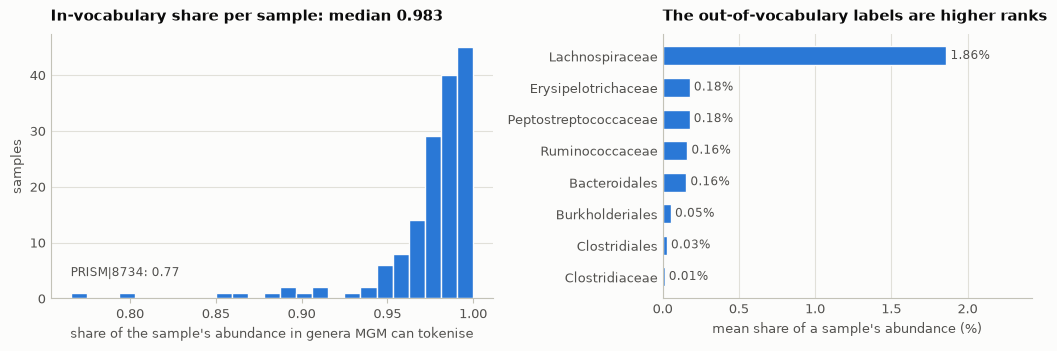

In [19]:
share = coverage["abundance_in_vocab"]
outside_share = 100 * genus_table[outside].div(genus_table.sum(axis=1), axis=0).mean()
outside_share = outside_share.sort_values()

fig, (ax_hist, ax_bar) = plt.subplots(
    1, 2, figsize=(10.5, 3.6), gridspec_kw={"width_ratios": [1.2, 1]}
)
ax_hist.hist(share, bins=25, color=BLUE)
ax_hist.annotate(
    f"{share.idxmin()}: {share.min():.2f}",
    (share.min(), 1),
    xytext=(0, 12),
    textcoords="offset points",
    color=INK_2,
    fontsize=8.5,
)
ax_hist.set_xlabel("share of the sample's abundance in genera MGM can tokenise")
ax_hist.set_ylabel("samples")
ax_hist.set_title(f"In-vocabulary share per sample: median {share.median():.3f}")
value_grid(ax_hist)

bars = ax_bar.barh(
    [genus.removeprefix("g__") for genus in outside_share.index],
    outside_share,
    height=0.6,
    color=BLUE,
)
ax_bar.bar_label(
    bars, labels=[f"{v:.2f}%" for v in outside_share], padding=3, color=INK_2, fontsize=8.5
)
ax_bar.set_xlim(0, outside_share.max() * 1.3)
ax_bar.set_xlabel("mean share of a sample's abundance (%)")
ax_bar.set_title("The out-of-vocabulary labels are higher ranks")
value_grid(ax_bar, "x")
ax_bar.tick_params(axis="y", length=0)
fig.tight_layout()
plt.show()

MGM sees almost all of most PRISM profiles (median 98.3%, minimum 76.5%); on average, most of
what it misses is unclassified Lachnospiraceae, which MetaPhlAn2 names at family level.

## 7. Takeaways for the modelling

All counts use the whole PRISM cohort; inside cross-validation every filter is refitted on the
training folds, so fold-level counts differ slightly.

- **Labels.** 155 PRISM samples: 68 CD, 53 UC, 34 Control (from D2 metadata, consistent with
  D1's IBD/Healthy file).
- **Re-closure.** Species totals have median 0.993, 15 samples are below 0.9 and one is at
  0.14, so the 200 species are re-closed before the 1e-4 presence threshold. In PRISM this
  changes no prevalence decision at 5%, 10% or 20%, and CLR is unaffected by it anyway.
- **Prevalence filter.** 184 / 151 / 109 of the 200 species pass at 5% / 10% / 20%
  (ablation A3); 6 species are absent from every PRISM sample.
- **Zero filter.** At 50%, T466 keeps 427 of 466 targets and TALL 6,948 of 8,848. C18-neg and
  C8-pos features are zero most often, HILIC-neg least.
- **Target scale.** The D1 metabolome is total-sum normalised per LC-MS method (1,000,000 per
  sample and method), so the targets are relative abundances within a method, not absolute
  intensities. Detected values are mostly far above 1, so the +1 in log10(x + 1) matters
  mainly for zeros, which become a separate spike at 0.
- **D2.** Over Franzosa's PRISM rows: 354 prevalent genera (brief: 350 over all 220 samples),
  214 shared by all six datasets (213), 461 in the union (460), 241 shared with iHMP (241).
- **Duplicates.** The 53 flagged ERAWIJANTARI samples are YACHIDA metagenomes (identical
  profiles), which leaves 1,503 unique source metagenomes.
- **iHMP.** No zeros, 8.2% missing values, scattered over samples and LC-MS methods and more
  frequent in faint features: NaN behaves like "not detected" (a pattern, not a proof).
- **MGM.** 59 of the 67 D1 genera are in MGM's vocabulary; in-vocabulary genera carry a median
  98.3% of a PRISM sample's abundance (minimum 76.5%).
- **External cohort.** Not opened here: nothing above was chosen with NLIBD in view.